# Example 3.6: Tournament vs. Roulette — Comparison of Selection Operators
**Chapter 3 · Four Bar Mechanisms with Genetic Algorithms**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Compare three selection operators —**tournament k=2**, **tournament k=3**, and **roulette**— by running 8 independent runs to minimize $f(x)=(x-3.7)^2+0.5\,\sin(5x)$ with `n_pop=36`, `n_gen=70`, `Pm=0.08`.

**Objective:** Analyze the selection pressure of each operator: tournament k=3 exerts higher pressure than k=2, while roulette selection is proportional to relative fitness.

In [1]:
# ── Imports─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [2]:
# ── Objective function──────────────────────────────────────────────────────
def f_obj(x):
    return (x - 3.7)**2 + 0.5 * sin(5 * x)

def ga_torneo(seed, n_pop=36, n_gen=70, pm=0.08, k=3):
    """GA with tournament selection of size k."""
    rng = random.default_rng(seed)
    pop = rng.uniform(0, 10, n_pop);  hist = []
    for _ in range(n_gen):
        fit = array([f_obj(x) for x in pop]);  hist.append(fit.min())
        padres = array([pop[c[argmin(fit[c])]]
                        for c in [rng.choice(n_pop, k, replace=False)
                                  for __ in range(n_pop)]])
        hijos = []
        for i in range(0, n_pop - 1, 2):
            a = rng.uniform(0, 1)
            hijos += [a*padres[i]+(1-a)*padres[i+1],
                       (1-a)*padres[i]+a*padres[i+1]]
        pop = clip(array(hijos[:n_pop]), 0, 10)
        mask = rng.random(n_pop) < pm
        pop[mask] += rng.normal(0, 0.3, int(mask.sum()))
        pop = clip(pop, 0, 10)
    best = pop[argmin(array([f_obj(x) for x in pop]))]
    return array(hist), best

def ga_ruleta(seed, n_pop=36, n_gen=70, pm=0.08):
    """GA with proportional selection (roulette wheel)."""
    rng = random.default_rng(seed)
    pop = rng.uniform(0, 10, n_pop);  hist = []
    for _ in range(n_gen):
        fit = array([f_obj(x) for x in pop]);  hist.append(fit.min())
        fit_inv = 1.0 / (fit - fit.min() + 1e-6)
        probs = fit_inv / fit_inv.sum()
        padres = pop[rng.choice(n_pop, n_pop, p=probs)]
        hijos = []
        for i in range(0, n_pop - 1, 2):
            a = rng.uniform(0, 1)
            hijos += [a*padres[i]+(1-a)*padres[i+1],
                       (1-a)*padres[i]+a*padres[i+1]]
        pop = clip(array(hijos[:n_pop]), 0, 10)
        mask = rng.random(n_pop) < pm
        pop[mask] += rng.normal(0, 0.3, int(mask.sum()))
        pop = clip(pop, 0, 10)
    best = pop[argmin(array([f_obj(x) for x in pop]))]
    return array(hist), best

# ── Experiment: 8 seeds───────────────────────────────────────────────
N_SEEDS = 8
hists_t2 = []; hists_t3 = []; hists_rul = []
best_t2  = []; best_t3  = []; best_rul  = []

for s in range(N_SEEDS):
    h, bx = ga_torneo(s, k=2); hists_t2.append(h); best_t2.append(f_obj(bx))
    h, bx = ga_torneo(s, k=3); hists_t3.append(h); best_t3.append(f_obj(bx))
    h, bx = ga_ruleta(s);       hists_rul.append(h); best_rul.append(f_obj(bx))

hists_t2 = array(hists_t2); hists_t3 = array(hists_t3); hists_rul = array(hists_rul)

for label, bests in [('Tournament k=2', best_t2),
                      ('Tournament k=3', best_t3),
                      ('Roulette',       best_rul)]:
    print(f"{label}:  mean f* = {mean(bests):.4f}  "
          f"std = {std(bests):.5f}  min = {min(bests):.4f}")



Tournament k=2:  mean f* = -0.3453  std = 0.27338  min = -0.4486
Tournament k=3:  mean f* = -0.4486  std = 0.00000  min = -0.4486
Roulette:  mean f* = -0.4486  std = 0.00001  min = -0.4486


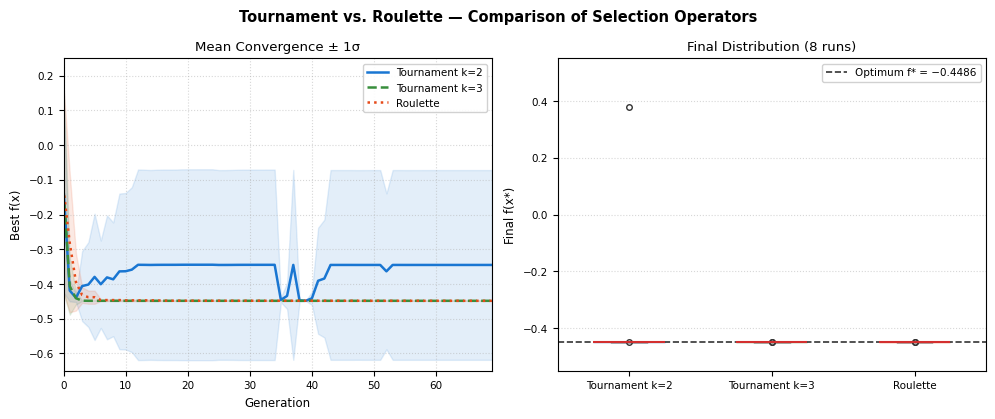

In [4]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# ── Systematic Naming ────────────────────────────────────────────────────────
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_3.6_tournament_vs_roulette"
except Exception:
    notebook_name = "Figure_3.6_tournament_vs_roulette"

# ── Springer Professional Plot Settings ──────────────────────────────────────
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'font.size': 8,
    'axes.labelsize': 8.5,
    'axes.titlesize': 9.5,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'legend.fontsize': 7.5
})

gens = np.arange(len(hists_t2[0]))

# ── Figure Layout ────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))

# Plot 1: Mean Convergence
for h_arr, col, ls, lbl in [
        (hists_t2, '#1976D2', '-',  'Tournament k=2'),
        (hists_t3, '#388E3C', '--', 'Tournament k=3'),
        (hists_rul, '#E64A19', ':',  'Roulette')]:
    m = np.mean(h_arr, axis=0)
    s_ = np.std(h_arr, axis=0)
    ax1.plot(gens, m, color=col, ls=ls, lw=1.8, label=lbl)
    ax1.fill_between(gens, m - s_, m + s_, alpha=0.12, color=col)

ax1.set_xlabel('Generation')
ax1.set_ylabel('Best f(x)')
ax1.set_title('Mean Convergence ± 1σ')
ax1.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='white')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.set_xlim(0, max(gens))
# Margin expansion to avoid overlapping legend/labels
ax1.set_ylim(-0.65, 0.25)

# Plot 2: Boxplot Final Distribution
bp = ax2.boxplot([best_t2, best_t3, best_rul],
                 tick_labels=['Tournament k=2', 'Tournament k=3', 'Roulette'],
                 patch_artist=True,
                 widths=0.5,
                 medianprops=dict(color='#D32F2F', linewidth=1.5))

colors = ['#1976D2', '#388E3C', '#E64A19']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor(color)
    patch.set_alpha(0.7)

# Customize whisker, cap, and flier properties for a cleaner look
for element in ['whiskers', 'caps']:
    plt.setp(bp[element], color='#333333', linestyle='-')
plt.setp(bp['fliers'], marker='o', markerfacecolor='none', markeredgecolor='#333333', markersize=4)

ax2.axhline(-0.4486, color='#333333', ls='--', lw=1.2, label='Optimum f* = −0.4486')
ax2.set_ylabel('Final f(x*)')
ax2.set_title('Final Distribution (8 runs)')
ax2.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='white')
ax2.grid(axis='y', linestyle=':', alpha=0.5)

# Adjust y-limits to make room for the legend
ax2.set_ylim(-0.55, 0.55)

plt.suptitle('Tournament vs. Roulette — Comparison of Selection Operators', fontsize=10.5, fontweight='bold', y=0.98)
plt.tight_layout()

# ── Exporting double format for publishers ─────────────────────────────────
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()